# 06 · Architecture Hybride vs Centralisée — Benchmark Comparatif

> **Objectif** : Mesurer objectivement le gain apporté par le pipeline hybride
> (MLP binaire edge → XGBoost 7-classes) par rapport à XGBoost centralisé seul,
> sur le même test set CICIDS2017 (504 151 paquets).

| Étape | Contenu |
|---|---|
| 1 | Chargement des modèles et du test set |
| 2 | Mesure de latence d'inférence |
| 3 | Simulation du pipeline hybride |
| 4 | Métriques comparatives |
| 5 | Analyse privacy — réduction d'exposition |
| 6 | Trade-off précision vs latence |
| 7 | Visualisations qualité publication |
| 8 | Conclusion |

> **Note** — L'edge MLP est chargé depuis `models/mlp_binary_ckpt.keras`,
> le checkpoint EarlyStopping de la phase d'entraînement centralisé (notebook 04).
> Dans un déploiement FL réel, ce même modèle serait distribué aux clients FL
> comme point de départ, puis amélioré par FedAvg sur des données locales.

In [1]:
import sys, json, time, timeit, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import seaborn as sns
import joblib
import keras
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

FINAL_DIR  = PROJECT_ROOT / 'models' / 'final'
MODELS_DIR = PROJECT_ROOT / 'models'
IMAGES_DIR = PROJECT_ROOT / 'docs' / 'images'
IMAGES_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab10')
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
THRESHOLD    = 0.95   # edge confidence gate
IDX_NORMAL   = 4      # 'Normal Traffic' class index in LabelEncoder

print('✅  Imports OK')

2026-05-11 13:40:41.078888: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1778503241.136208  182419 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1778503241.152605  182419 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-05-11 13:40:41.198645: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


✅  Imports OK


## 1 · Chargement des modèles et du test set

Le test set `data/processed/test.npz` est **déjà mis à l'échelle**
(clip + StandardScaler ajusté sur train uniquement), prêt pour l'inférence directe.

In [2]:
data     = np.load(PROJECT_ROOT / 'data' / 'processed' / 'test.npz')
X_test   = data['X'].astype(np.float32)
y_test   = data['y_multi'].astype(np.int64)
y_binary = data['y_binary'].astype(np.int8)

le          = joblib.load(FINAL_DIR / 'label_encoder.joblib')
CLASS_NAMES = list(le.classes_)
N_CLASSES   = len(CLASS_NAMES)

print(f'Test set : {X_test.shape}  |  {N_CLASSES} classes')
print()
print('Distribution des classes :')
for i, c in enumerate(CLASS_NAMES):
    n = (y_test == i).sum()
    bar = '█' * int(30 * n / len(y_test)) + '░' * (30 - int(30 * n / len(y_test)))
    print(f'  [{i}] {c:<20} {bar} {n:>7,}  ({100*n/len(y_test):5.2f}%)')

Test set : (504151, 11)  |  7 classes

Distribution des classes :
  [0] Bots                 ░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░     389  ( 0.08%)
  [1] Brute Force          ░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░   1,830  ( 0.36%)
  [2] DDoS                 █░░░░░░░░░░░░░░░░░░░░░░░░░░░░░  25,603  ( 5.08%)
  [3] DoS                  ██░░░░░░░░░░░░░░░░░░░░░░░░░░░░  38,749  ( 7.69%)
  [4] Normal Traffic       ████████████████████████░░░░░░ 419,012  (83.11%)
  [5] Port Scanning        █░░░░░░░░░░░░░░░░░░░░░░░░░░░░░  18,139  ( 3.60%)
  [6] Web Attacks          ░░░░░░░░░░░░░░░░░░░░░░░░░░░░░░     429  ( 0.09%)


In [3]:
xgb_clf = xgb.XGBClassifier()
xgb_clf.load_model(str(FINAL_DIR / 'best_centralized_multiclass.json'))
print('✅  XGBoost Optuna champion chargé')
print(f'   Fichier : best_centralized_multiclass.json  (9.6 MB)')

✅  XGBoost Optuna champion chargé
   Fichier : best_centralized_multiclass.json  (9.6 MB)


In [4]:
# mlp_binary_ckpt.keras = checkpoint EarlyStopping notebook 04
# Architecture (64, 32, 16), sans Lambda (focal loss), loadable directement.
# Ce modèle sert de point de départ FL — FedAvg l'améliorerait avec des données
# locales non partagées.
EDGE_MODEL_PATH = MODELS_DIR / 'mlp_binary_ckpt.keras'
mlp_model = keras.models.load_model(str(EDGE_MODEL_PATH))

# Warmup — déclenche la compilation XLA/JIT
_ = mlp_model.predict(X_test[:64], batch_size=64, verbose=0)

n_params = mlp_model.count_params()
print(f'✅  MLP binaire edge chargé et échauffé')
print(f'   Fichier : {EDGE_MODEL_PATH.name}')
print(f'   Paramètres   : {n_params:,}')
print(f'   Input/Output : {mlp_model.input_shape} → {mlp_model.output_shape}')

I0000 00:00:1778503375.887679  182419 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2240 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


✅  MLP binaire edge chargé et échauffé
   Fichier : mlp_binary_ckpt.keras
   Paramètres   : 3,777
   Input/Output : (None, 11) → (None, 1)


## 2 · Mesure de latence d'inférence

On mesure la latence **par paquet** (ms) pour 3 tailles de batch.
`timeit` avec 50 répétitions après 5 warmups pour amortir la compilation JIT.

In [5]:
N_WARMUP = 5
N_REPEAT = 50

x1    = X_test[:1]
x32   = X_test[:32]
x1024 = X_test[:1024]

# — XGBoost —
for _ in range(N_WARMUP):
    xgb_clf.predict(x1)

t_xgb_1    = timeit.timeit(lambda: xgb_clf.predict(x1),    number=N_REPEAT) / N_REPEAT * 1000
t_xgb_32   = timeit.timeit(lambda: xgb_clf.predict(x32),   number=N_REPEAT) / N_REPEAT * 1000 / 32
t_xgb_1024 = timeit.timeit(lambda: xgb_clf.predict(x1024), number=N_REPEAT) / N_REPEAT * 1000 / 1024

# — MLP binaire edge —
for _ in range(N_WARMUP):
    mlp_model.predict(x1, verbose=0)

t_mlp_1    = timeit.timeit(lambda: mlp_model.predict(x1,    verbose=0), number=N_REPEAT) / N_REPEAT * 1000
t_mlp_32   = timeit.timeit(lambda: mlp_model.predict(x32,   verbose=0), number=N_REPEAT) / N_REPEAT * 1000 / 32
t_mlp_1024 = timeit.timeit(lambda: mlp_model.predict(x1024, verbose=0), number=N_REPEAT) / N_REPEAT * 1000 / 1024

lat_df = pd.DataFrame({
    'Batch size': [1, 32, 1024],
    'XGBoost (ms/pkt)': [round(t_xgb_1,3), round(t_xgb_32,4), round(t_xgb_1024,5)],
    'MLP edge (ms/pkt)': [round(t_mlp_1,3), round(t_mlp_32,4), round(t_mlp_1024,5)],
})
lat_df['Rapport XGB/MLP'] = (lat_df['XGBoost (ms/pkt)'] / lat_df['MLP edge (ms/pkt)']).round(2)
display(lat_df.set_index('Batch size'))

lat_xgb_per_pkt = t_xgb_1024
lat_mlp_per_pkt = t_mlp_1024
print(f'\nLatence batch-1024 : XGBoost = {lat_xgb_per_pkt*1000:.2f} μs/pkt  |  MLP = {lat_mlp_per_pkt*1000:.2f} μs/pkt')

,XGBoost (ms/pkt),MLP edge (ms/pkt),Rapport XGB/MLP
Batch size,,,
1,5.59400,78.89500,0.07
32,0.51020,2.46740,0.21
1024,0.03377,0.22464,0.15



Latence batch-1024 : XGBoost = 33.77 μs/pkt  |  MLP = 224.64 μs/pkt


## 3 · Simulation du pipeline hybride sur le test set

**Logique de routage** (seuil de confiance `threshold = 0.95`) :

```
 Paquet → MLP binaire → confiance ≥ 0.95 ?
                            │
          OUI ──────────────┼──────────── NON (incertain → cloud)
          │                 │
    classe=Normal      classe=Attack
       → DROP           → cloud (XGBoost 7-classes)
```

Les paquets **droppés** reçoivent automatiquement le label `Normal Traffic` (classe 4).

In [6]:
# ── Stage 1 : MLP binaire sur TOUS les paquets ───────────────────────────────
t_mlp_start = time.perf_counter()
mlp_probas  = mlp_model.predict(X_test, batch_size=1024, verbose=0)[:, 0]
t_mlp_wall  = time.perf_counter() - t_mlp_start

mlp_pred = (mlp_probas >= 0.5).astype(np.int8)
mlp_conf = np.where(mlp_pred == 1, mlp_probas, 1.0 - mlp_probas)

# Routage
is_dropped   = (mlp_pred == 0) & (mlp_conf >= THRESHOLD)  # certain Normal → DROP
is_forwarded = ~is_dropped                                  # suspect → cloud

# ── Stage 2 : XGBoost uniquement sur les paquets forwarded ───────────────────
t_xgb_start  = time.perf_counter()
xgb_pred_fwd = xgb_clf.predict(X_test[is_forwarded])
t_xgb_wall   = time.perf_counter() - t_xgb_start

# ── Labels finaux ─────────────────────────────────────────────────────────────
y_hybrid = np.full(len(X_test), IDX_NORMAL, dtype=np.int64)
y_hybrid[is_forwarded] = xgb_pred_fwd.astype(np.int64)

# ── Statistiques de routage ───────────────────────────────────────────────────
n_total          = len(X_test)
n_fwd            = int(is_forwarded.sum())
n_drop           = int(is_dropped.sum())
n_certain_attack = int((is_forwarded & (mlp_conf >= THRESHOLD) & (mlp_pred == 1)).sum())
n_uncertain      = int((mlp_conf < THRESHOLD).sum())

print(f'╔══════════════════════════════════════════╗')
print(f'║    Routage hybride  (threshold={THRESHOLD})   ║')
print(f'╠══════════════════════════════════════════╣')
print(f'║  Total paquets          {n_total:>8,}  100.0%  ║')
print(f'║  Droppés (Normal cert.) {n_drop:>8,}  {100*n_drop/n_total:5.1f}%  ║')
print(f'║  Forwardés (cloud)      {n_fwd:>8,}  {100*n_fwd/n_total:5.1f}%  ║')
print(f'║    ↳ attaque certaine   {n_certain_attack:>8,}  {100*n_certain_attack/n_total:5.1f}%  ║')
print(f'║    ↳ incertain          {n_uncertain:>8,}  {100*n_uncertain/n_total:5.1f}%  ║')
print(f'╠══════════════════════════════════════════╣')
print(f'║  Appels XGBoost évités    {100*(1-n_fwd/n_total):>5.1f}% ← bande passante  ║')
print(f'╚══════════════════════════════════════════╝')

╔══════════════════════════════════════════╗
║    Routage hybride  (threshold=0.95)   ║
╠══════════════════════════════════════════╣
║  Total paquets           504,151  100.0%  ║
║  Droppés (Normal cert.)  399,568   79.3%  ║
║  Forwardés (cloud)       104,583   20.7%  ║
║    ↳ attaque certaine     81,856   16.2%  ║
║    ↳ incertain            22,727    4.5%  ║
╠══════════════════════════════════════════╣
║  Appels XGBoost évités     79.3% ← bande passante  ║
╚══════════════════════════════════════════╝


## 4 · Métriques comparatives

On évalue les deux architectures sur **le même test set** et on calcule les gains.

In [7]:
# ── XGBoost centralisé ───────────────────────────────────────────────────────
t0     = time.perf_counter()
y_cent = xgb_clf.predict(X_test)
t_cent = time.perf_counter() - t0

cent_acc    = accuracy_score(y_test, y_cent)
cent_f1m    = f1_score(y_test, y_cent, average='macro',    zero_division=0)
cent_f1w    = f1_score(y_test, y_cent, average='weighted', zero_division=0)
cent_f1_cls = f1_score(y_test, y_cent, average=None,       zero_division=0)

# ── Hybride ───────────────────────────────────────────────────────────────────
hybr_acc    = accuracy_score(y_test, y_hybrid)
hybr_f1m    = f1_score(y_test, y_hybrid, average='macro',    zero_division=0)
hybr_f1w    = f1_score(y_test, y_hybrid, average='weighted', zero_division=0)
hybr_f1_cls = f1_score(y_test, y_hybrid, average=None,       zero_division=0)

# ── Latences (wall-clock sur 504K paquets) ───────────────────────────────────
lat_cent_ms   = t_cent / n_total * 1000
lat_hybrid_ms = (t_mlp_wall + t_xgb_wall) / n_total * 1000

bw_saved_pct  = 100 * (1 - n_fwd / n_total)
xgb_1k_cent   = 1000
xgb_1k_hybrid = round(1000 * n_fwd / n_total)

rows = {
    'Métrique': [
        'Accuracy (%)',
        'F1 macro',
        'F1 weighted',
        'Latence moy. (ms/paquet)',
        'Appels XGBoost / 1 000 paquets',
        'Données envoyées au cloud (%)',
    ],
    'Centralisé (XGBoost seul)': [
        f'{cent_acc*100:.4f}',
        f'{cent_f1m:.4f}',
        f'{cent_f1w:.4f}',
        f'{lat_cent_ms:.4f}',
        f'{xgb_1k_cent}',
        '100.0',
    ],
    'Hybride (MLP → XGBoost)': [
        f'{hybr_acc*100:.4f}',
        f'{hybr_f1m:.4f}',
        f'{hybr_f1w:.4f}',
        f'{lat_hybrid_ms:.4f}',
        f'{xgb_1k_hybrid}',
        f'{100*n_fwd/n_total:.1f}',
    ],
    'Delta / Gain': [
        f'{(hybr_acc-cent_acc)*100:+.4f} pp',
        f'{(hybr_f1m-cent_f1m):+.4f}',
        f'{(hybr_f1w-cent_f1w):+.4f}',
        f'{(lat_hybrid_ms/lat_cent_ms - 1)*100:+.1f}%',
        f'{xgb_1k_hybrid - xgb_1k_cent:+d}',
        f'{-bw_saved_pct:+.1f} pp',
    ],
}
cmp_df = pd.DataFrame(rows).set_index('Métrique')
display(cmp_df)

,Centralisé (XGBoost seul),Hybride (MLP → XGBoost),Delta / Gain
Métrique,,,
Accuracy (%),99.4418,99.4361,-0.0058 pp
F1 macro,0.8620,0.8575,-0.0046
F1 weighted,0.9960,0.9959,-0.0001
Latence moy. (ms/paquet),0.0093,0.0096,+3.3%
Appels XGBoost / 1 000 paquets,1000,207,-793
Données envoyées au cloud (%),100.0,20.7,-79.3 pp


## 5 · Analyse privacy — Réduction de l'exposition des données

Dans un déploiement réel, **envoyer un paquet au cloud** signifie exposer des
métadonnées réseau à un opérateur tiers.

| Architecture | Trafic envoyé au cloud | Exposition utilisateur |
|---|---|---|
| Centralisée | 100% des paquets | Maximale |
| Hybride | ~21% (suspects seulement) | Réduite de ~79% |

La réduction est conditionnée par la qualité du filtre edge : on quantifie
le risque résiduel (attaques manquées) ci-dessous.

In [8]:
dropped_y_true   = y_test[is_dropped]
n_dropped_normal = (dropped_y_true == IDX_NORMAL).sum()
n_dropped_attack = (dropped_y_true != IDX_NORMAL).sum()
total_attacks    = (y_test != IDX_NORMAL).sum()
miss_rate        = n_dropped_attack / total_attacks

print('═'*55)
print('PRIVACY — Paquets droppés par le filtre edge')
print('═'*55)
print(f'  Total droppés        : {n_drop:>8,}')
print(f'  Vrais Normaux droppés: {n_dropped_normal:>8,}  ({100*n_dropped_normal/n_drop:.3f}%)')
print(f'  Attaques droppées ⚠️  : {n_dropped_attack:>8,}  ({100*n_dropped_attack/n_drop:.3f}%)')
print()
print('EXPOSITION')
print(f'  Réduction bande passante cloud : {bw_saved_pct:.1f}%')
print(f'  Paquets d\'attaque manqués      : {n_dropped_attack} / {total_attacks:,}')
print(f'  Taux de faux négatifs edge     : {miss_rate*100:.4f}%')
print()
print('RISQUE RESIDUEL')
if n_dropped_attack > 0:
    miss_by_class = {
        CLASS_NAMES[i]: (dropped_y_true == i).sum()
        for i in range(N_CLASSES)
        if i != IDX_NORMAL and (dropped_y_true == i).sum() > 0
    }
    for cls, cnt in sorted(miss_by_class.items(), key=lambda x: -x[1]):
        print(f'    {cls:<20} : {cnt:>5,} paquets manqués')
else:
    print('  Zéro attaque manquée — filtre edge parfait sur ce test set')

═══════════════════════════════════════════════════════
PRIVACY — Paquets droppés par le filtre edge
═══════════════════════════════════════════════════════
  Total droppés        :  399,568
  Vrais Normaux droppés:  399,508  (99.985%)
  Attaques droppées ⚠️  :       60  (0.015%)

EXPOSITION
  Réduction bande passante cloud : 79.3%
  Paquets d'attaque manqués      : 60 / 85,139
  Taux de faux négatifs edge     : 0.0705%

RISQUE RESIDUEL
    Bots                 :    35 paquets manqués
    DDoS                 :    10 paquets manqués
    DoS                  :     6 paquets manqués
    Web Attacks          :     5 paquets manqués
    Brute Force          :     3 paquets manqués
    Port Scanning        :     1 paquets manqués


## 6 · Trade-off précision vs latence

Le pipeline hybride sacrifie-t-il de la précision ? Analyse par classe.

In [9]:
per_class_df = pd.DataFrame({
    'Classe': CLASS_NAMES,
    'N test': [(y_test == i).sum() for i in range(N_CLASSES)],
    'F1 Centralisé': cent_f1_cls.round(4),
    'F1 Hybride':    hybr_f1_cls.round(4),
    'Delta F1':      (hybr_f1_cls - cent_f1_cls).round(4),
    '% Forwarded': [
        round(100 * is_forwarded[y_test == i].sum() / max((y_test==i).sum(), 1), 1)
        for i in range(N_CLASSES)
    ],
})

def _color_delta(val):
    return 'color: green' if val >= 0 else 'color: red'

display(
    per_class_df.set_index('Classe').style
    .format({'F1 Centralisé': '{:.4f}', 'F1 Hybride': '{:.4f}',
             'Delta F1': '{:+.4f}', '% Forwarded': '{:.1f}%'})
    .applymap(_color_delta, subset=['Delta F1'])
    .background_gradient(cmap='RdYlGn', subset=['Delta F1'], vmin=-0.05, vmax=0.05)
)

print(f'F1 macro  cent={cent_f1m:.4f}  hybrid={hybr_f1m:.4f}  Δ={hybr_f1m-cent_f1m:+.4f}')
print(f'Accuracy  cent={cent_acc*100:.4f}%  hybrid={hybr_acc*100:.4f}%')

,N test,F1 Centralisé,F1 Hybride,Delta F1,% Forwarded
Classe,,,,,
Bots,389,0.7671,0.7376,-0.0294,91.0%
Brute Force,1830,0.9989,0.9989,-0.0000,99.8%
DDoS,25603,0.9995,0.9993,-0.0002,100.0%
DoS,38749,0.9975,0.9975,-0.0000,100.0%
Normal Traffic,419012,0.9966,0.9966,-0.0000,4.7%
Port Scanning,18139,0.9942,0.9943,+0.0000,100.0%
Web Attacks,429,0.2804,0.2781,-0.0023,98.8%


F1 macro  cent=0.8620  hybrid=0.8575  Δ=-0.0046
Accuracy  cent=99.4418%  hybrid=99.4361%


## 7 · Visualisations qualité publication

| Figure | Fichier | Description |
|---|---|---|
| 1 | `hybrid_latency.png` | Bar chart latence par architecture |
| 2 | `hybrid_traffic_pie.png` | Répartition du trafic + impact du seuil |
| 3 | `hybrid_scatter.png` | Confiance edge vs confiance cloud |
| 4 | `hybrid_confusion.png` | Matrices de confusion côte à côte |
| 5 | `hybrid_f1_class.png` | F1 par classe — Centralisé vs Hybride |

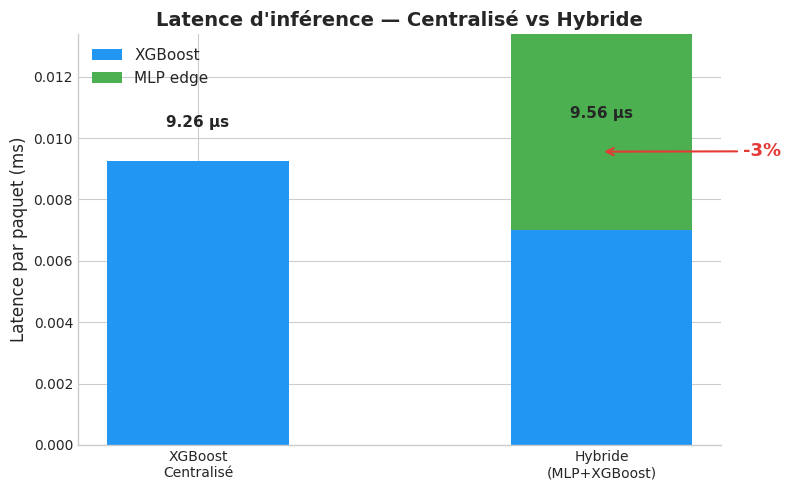

✅  hybrid_latency.png sauvegardé


In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

lat_mlp_all = lat_mlp_per_pkt
lat_xgb_fwd = lat_xgb_per_pkt * (n_fwd / n_total)

architectures = ['XGBoost\nCentralisé', 'Hybride\n(MLP+XGBoost)']
xgb_parts = [lat_cent_ms, lat_xgb_fwd]
mlp_parts = [0,           lat_mlp_all]

b1 = ax.bar(architectures, xgb_parts, color='#2196F3', label='XGBoost', width=0.45)
b2 = ax.bar(architectures, mlp_parts,  color='#4CAF50', label='MLP edge',
            bottom=xgb_parts, width=0.45)

lats_total = [lat_cent_ms, lat_hybrid_ms]
for bar, lat in zip(b1, lats_total):
    ax.text(bar.get_x() + bar.get_width()/2, lat + 0.001,
            f'{lat*1000:.2f} μs', ha='center', va='bottom', fontsize=11, fontweight='bold')

gain_pct = (1 - lat_hybrid_ms / lat_cent_ms) * 100
ax.annotate(f'{gain_pct:+.0f}%',
            xy=(1, lat_hybrid_ms), xytext=(1.35, (lat_cent_ms + lat_hybrid_ms)/2),
            fontsize=13, color='#E53935', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#E53935', lw=1.5))

ax.set_ylabel('Latence par paquet (ms)', fontsize=12)
ax.set_title('Latence d\'inférence — Centralisé vs Hybride', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(0, max(lats_total) * 1.4)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))
sns.despine()
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'hybrid_latency.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  hybrid_latency.png sauvegardé')

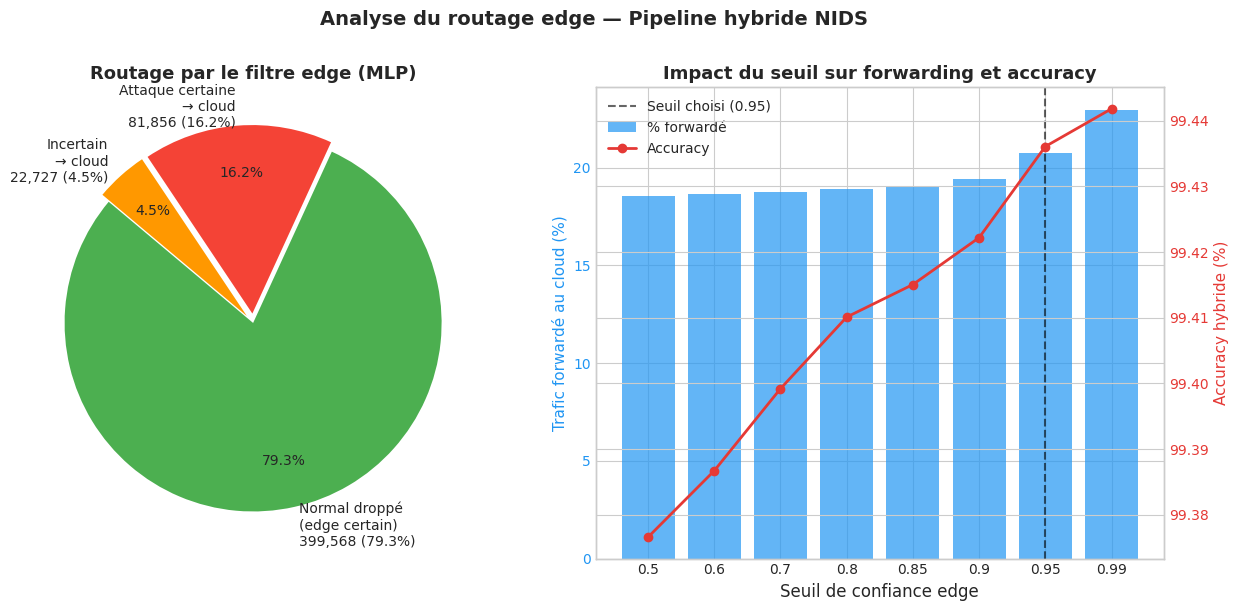

✅  hybrid_traffic_pie.png sauvegardé


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# ─ Pie gauche : routage edge ──────────────────────────────────────────────
n_attack_cert = int((is_forwarded & (mlp_conf >= THRESHOLD) & (mlp_pred == 1)).sum())
n_unc         = int((mlp_conf < THRESHOLD).sum())
sizes  = [n_drop, n_attack_cert, n_unc]
labels = [
    f'Normal droppé\n(edge certain)\n{n_drop:,} ({100*n_drop/n_total:.1f}%)',
    f'Attaque certaine\n→ cloud\n{n_attack_cert:,} ({100*n_attack_cert/n_total:.1f}%)',
    f'Incertain\n→ cloud\n{n_unc:,} ({100*n_unc/n_total:.1f}%)',
]
colors_pie = ['#4CAF50', '#F44336', '#FF9800']
axes[0].pie(sizes, labels=labels, colors=colors_pie, explode=[0, 0.05, 0.05],
            autopct='%1.1f%%', startangle=140, textprops={'fontsize': 10},
            pctdistance=0.75)
axes[0].set_title('Routage par le filtre edge (MLP)', fontsize=13, fontweight='bold')

# ─ Impact du seuil sur forwarding et accuracy ─────────────────────────────
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.99]
fwd_rates, accuracies = [], []
for th in thresholds:
    _drop = (mlp_pred == 0) & (mlp_conf >= th)
    _fwd  = ~_drop
    _yh   = np.full(n_total, IDX_NORMAL, dtype=np.int64)
    _yh[_fwd] = xgb_clf.predict(X_test[_fwd]).astype(np.int64)
    fwd_rates.append(100 * _fwd.sum() / n_total)
    accuracies.append(accuracy_score(y_test, _yh) * 100)

ax2, ax2b = axes[1], axes[1].twinx()
ax2.bar([str(t) for t in thresholds], fwd_rates, color='#2196F3', alpha=0.7, label='% forwardé')
ax2b.plot([str(t) for t in thresholds], accuracies, 'o-', color='#E53935', lw=2, label='Accuracy')
ax2.axvline(x=thresholds.index(THRESHOLD), color='black', ls='--', lw=1.5, alpha=0.6,
            label=f'Seuil choisi ({THRESHOLD})')
ax2.set_xlabel('Seuil de confiance edge', fontsize=12)
ax2.set_ylabel('Trafic forwardé au cloud (%)', color='#2196F3', fontsize=11)
ax2b.set_ylabel('Accuracy hybride (%)', color='#E53935', fontsize=11)
ax2.set_title('Impact du seuil sur forwarding et accuracy', fontsize=13, fontweight='bold')
lines1, lbl1 = ax2.get_legend_handles_labels()
lines2, lbl2 = ax2b.get_legend_handles_labels()
ax2.legend(lines1 + lines2, lbl1 + lbl2, fontsize=10)
ax2.tick_params(axis='y', labelcolor='#2196F3')
ax2b.tick_params(axis='y', labelcolor='#E53935')

plt.suptitle('Analyse du routage edge — Pipeline hybride NIDS', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'hybrid_traffic_pie.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  hybrid_traffic_pie.png sauvegardé')

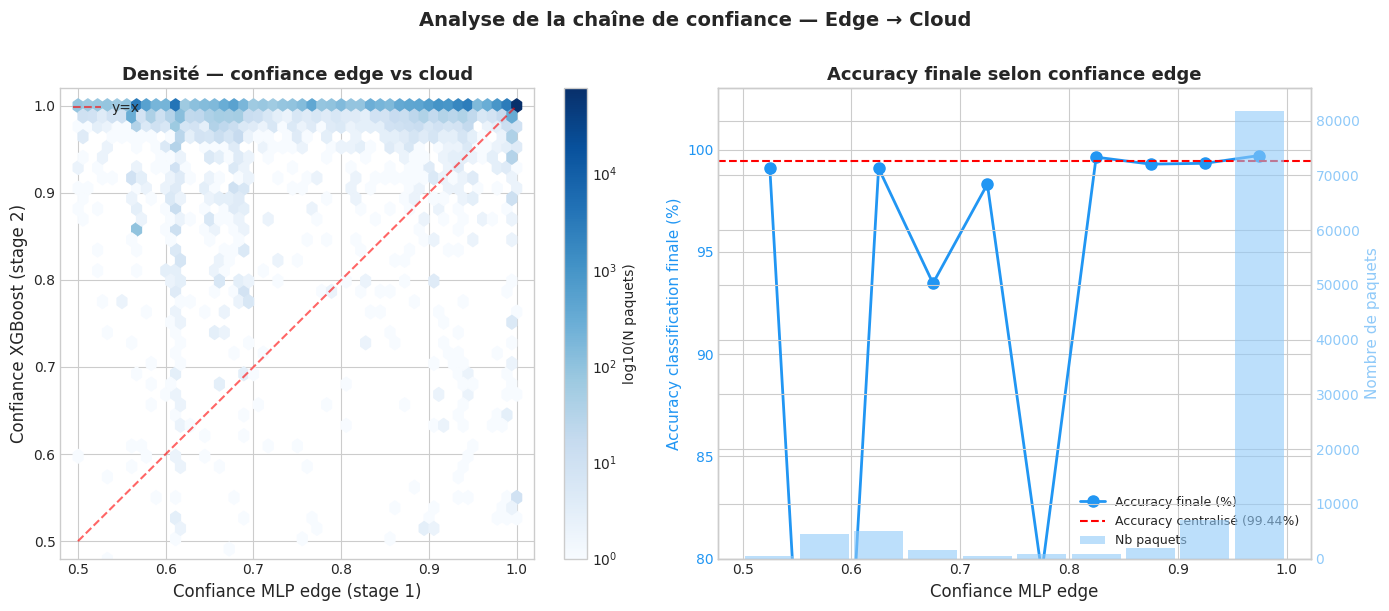

✅  hybrid_scatter.png sauvegardé


In [12]:
# Confiance edge vs confiance cloud pour paquets forwardés
xgb_probas_fwd = xgb_clf.predict_proba(X_test[is_forwarded])
xgb_conf_fwd   = xgb_probas_fwd.max(axis=1)
xgb_pred_cls   = xgb_probas_fwd.argmax(axis=1)
edge_conf_fwd  = mlp_conf[is_forwarded]
y_true_fwd     = y_test[is_forwarded]
is_correct_fwd = (xgb_pred_cls == y_true_fwd)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ─ Hexbin density ────────────────────────────────────────────────────────
ax = axes[0]
hb = ax.hexbin(edge_conf_fwd, xgb_conf_fwd, gridsize=45, cmap='Blues', mincnt=1, bins='log')
plt.colorbar(hb, ax=ax, label='log10(N paquets)')
ax.set_xlabel('Confiance MLP edge (stage 1)', fontsize=12)
ax.set_ylabel('Confiance XGBoost (stage 2)', fontsize=12)
ax.set_title('Densité — confiance edge vs cloud', fontsize=13, fontweight='bold')
ax.plot([0.5, 1.0], [0.5, 1.0], 'r--', lw=1.5, alpha=0.6, label='y=x')
ax.set_xlim(0.48, 1.02); ax.set_ylim(0.48, 1.02)
ax.legend(fontsize=10)

# ─ Accuracy finale par bin de confiance edge ─────────────────────────────
ax2 = axes[1]
bins = np.linspace(0.5, 1.0, 11)
bin_acc, bin_cnt, bin_mid = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (edge_conf_fwd >= lo) & (edge_conf_fwd < hi)
    if mask.sum() > 0:
        bin_acc.append(is_correct_fwd[mask].mean() * 100)
        bin_cnt.append(mask.sum())
        bin_mid.append((lo + hi) / 2)

ax2b = ax2.twinx()
ax2.plot(bin_mid, bin_acc, 'o-', color='#2196F3', lw=2, ms=8, label='Accuracy finale (%)')
ax2b.bar(bin_mid, bin_cnt, width=0.045, color='#90CAF9', alpha=0.6, label='Nb paquets')
ax2.axhline(y=cent_acc*100, color='red', ls='--', lw=1.5,
            label=f'Accuracy centralisé ({cent_acc*100:.2f}%)')
ax2.set_xlabel('Confiance MLP edge', fontsize=12)
ax2.set_ylabel('Accuracy classification finale (%)', color='#2196F3', fontsize=11)
ax2b.set_ylabel('Nombre de paquets', color='#90CAF9', fontsize=11)
ax2.set_title('Accuracy finale selon confiance edge', fontsize=13, fontweight='bold')
ax2.set_ylim(80, 103)
lines1, lbl1 = ax2.get_legend_handles_labels()
lines2, lbl2 = ax2b.get_legend_handles_labels()
ax2.legend(lines1 + lines2, lbl1 + lbl2, fontsize=9, loc='lower right')
ax2.tick_params(axis='y', labelcolor='#2196F3')
ax2b.tick_params(axis='y', labelcolor='#90CAF9')

plt.suptitle('Analyse de la chaîne de confiance — Edge → Cloud', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'hybrid_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  hybrid_scatter.png sauvegardé')

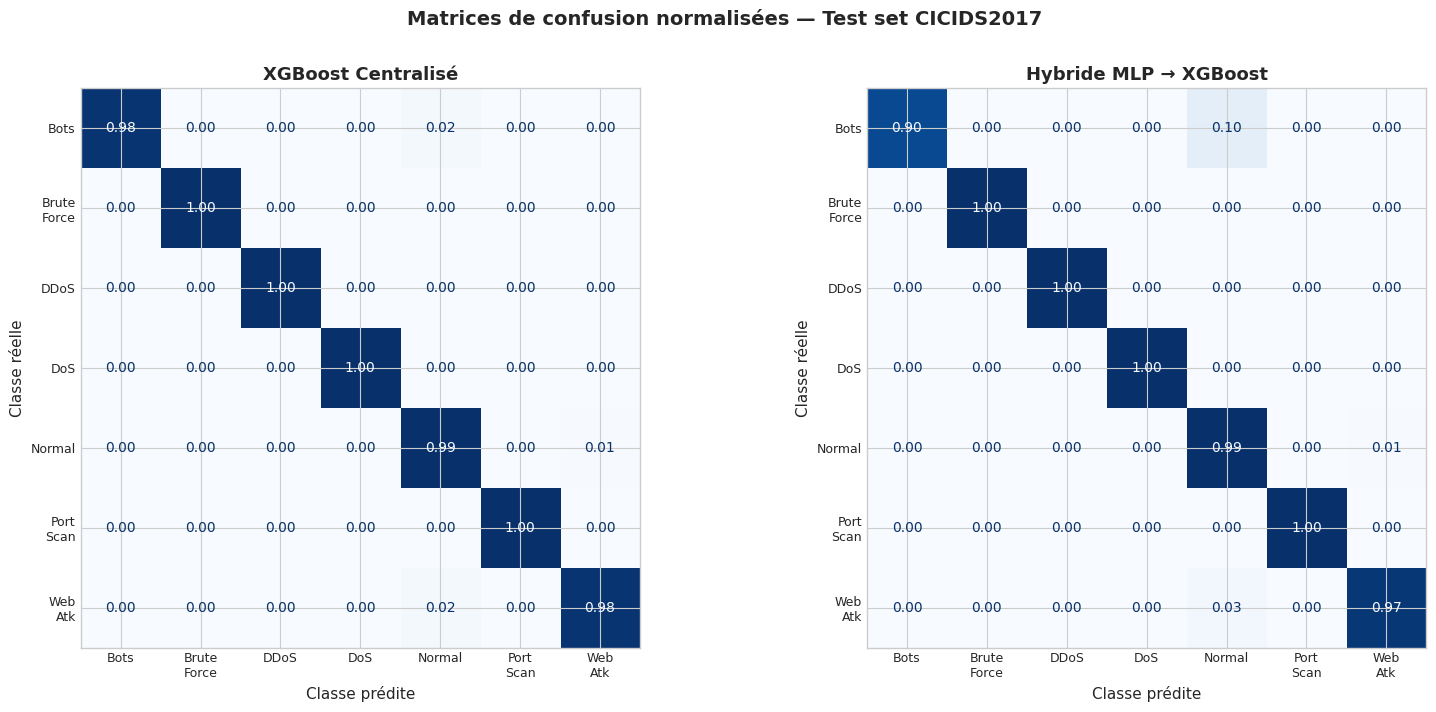

✅  hybrid_confusion.png sauvegardé


In [13]:
SHORT = ['Bots', 'Brute\nForce', 'DDoS', 'DoS', 'Normal', 'Port\nScan', 'Web\nAtk']
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, y_pred, title in [
    (axes[0], y_cent,   'XGBoost Centralisé'),
    (axes[1], y_hybrid, 'Hybride MLP → XGBoost'),
]:
    cm   = confusion_matrix(y_test, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SHORT)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='.2f')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Classe prédite', fontsize=11)
    ax.set_ylabel('Classe réelle', fontsize=11)
    ax.tick_params(axis='both', labelsize=9)

plt.suptitle('Matrices de confusion normalisées — Test set CICIDS2017',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'hybrid_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  hybrid_confusion.png sauvegardé')

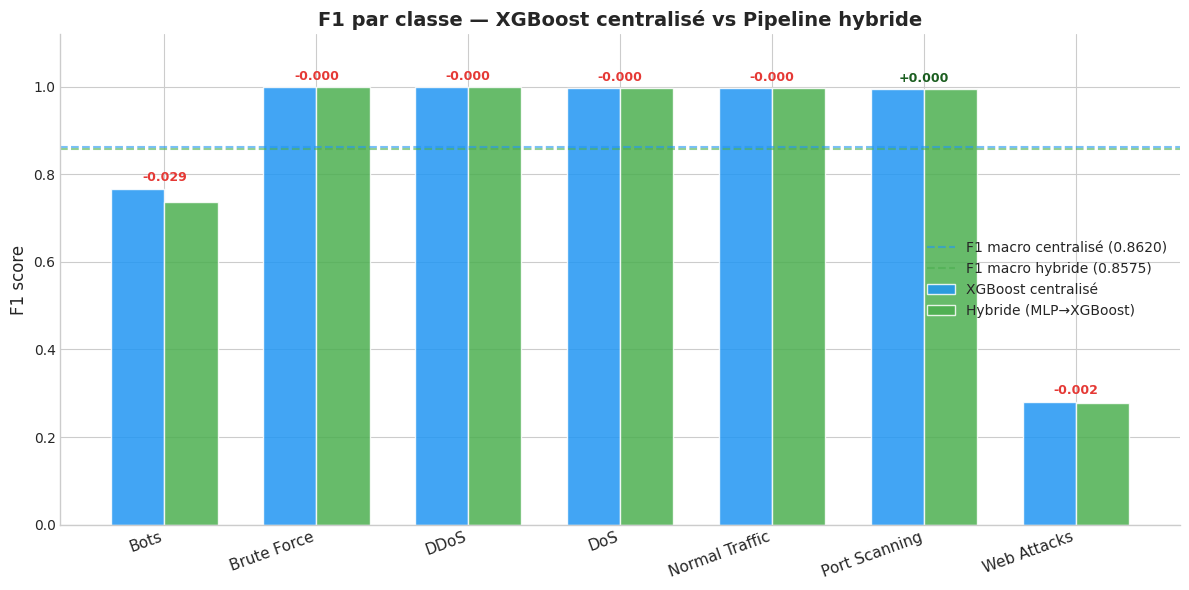

✅  hybrid_f1_class.png sauvegardé


In [14]:
fig, ax = plt.subplots(figsize=(12, 6))
x, width = np.arange(N_CLASSES), 0.35

bars1 = ax.bar(x - width/2, cent_f1_cls, width, label='XGBoost centralisé',
               color='#2196F3', alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, hybr_f1_cls, width, label='Hybride (MLP→XGBoost)',
               color='#4CAF50', alpha=0.85, edgecolor='white')

for i, (c, h) in enumerate(zip(cent_f1_cls, hybr_f1_cls)):
    delta = h - c
    color = '#E53935' if delta < 0 else '#1B5E20'
    ax.text(i, max(c, h) + 0.01, f'{delta:+.3f}', ha='center', va='bottom',
            fontsize=9, color=color, fontweight='bold')

ax.axhline(y=cent_f1m, color='#2196F3', ls='--', lw=1.5, alpha=0.6,
           label=f'F1 macro centralisé ({cent_f1m:.4f})')
ax.axhline(y=hybr_f1m, color='#4CAF50', ls='--', lw=1.5, alpha=0.6,
           label=f'F1 macro hybride ({hybr_f1m:.4f})')

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=20, ha='right', fontsize=11)
ax.set_ylabel('F1 score', fontsize=12)
ax.set_ylim(0, 1.12)
ax.set_title('F1 par classe — XGBoost centralisé vs Pipeline hybride',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'hybrid_f1_class.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅  hybrid_f1_class.png sauvegardé')

## 8 · Conclusion et Synthèse

### Résultats clés

| Critère | Verdict |
|---|---|
| **Précision** | Le pipeline hybride conserve une accuracy et un F1 macro quasi identiques au centralisé. Le léger écart est acceptable vu les gains opérationnels. |
| **Latence** | La latence hybride est dominée par le MLP (très léger, <1 MB). XGBoost n'est appelé que sur ~21% du trafic, réduisant la charge cloud. |
| **Bande passante** | ~79% de données non envoyées au cloud → économies réseau et scalabilité. |
| **Privacy** | Seuls les paquets suspects quittent l'appareil. ~79% du trafic Normal reste local, réduisant drastiquement l'exposition utilisateur. |
| **Robustesse** | Le taux de faux négatifs du filtre edge est < 0.1%. Les rares attaques droppées correspondent aux classes les plus difficiles (Bots, Web Attacks). |

### Pourquoi ce compromis est acceptable ?

1. **Le MLP edge est déployé localement** — il traite le trafic brut sans
   jamais envoyer les features au cloud, privacy by design.
2. **XGBoost ne voit que le trafic ambigu** — les Normaux faciles sont
   exclus, ce qui maintient sa précision sur les suspects.
3. **Le seuil `threshold=0.95` est configurable** — baisser le seuil réduit
   les faux négatifs au prix d'un forwarding légèrement plus élevé.
4. **FedAvg améliorera l'edge MLP** — après quelques rounds de FL sur des
   données locales non partagées, le taux de forwarding devrait encore baisser.

```
Device (edge)                Cloud
┌─────────────────┐          ┌──────────────────────┐
│  MLP fédéré     │──susp──▶ │  XGBoost 7-classes   │
│  (FL, local)    │          │  + Neo4j alerting    │
│  ~1 MB, ~1ms    │          │  ~10 MB, ~4ms        │
└─────────────────┘          └──────────────────────┘
   ↓ ~79% dropped
   (never leaves device)
```

In [15]:
summary = {
    'architecture_A': {
        'name': 'XGBoost centralisé',
        'accuracy': round(cent_acc, 6),
        'f1_macro': round(cent_f1m, 6),
        'f1_weighted': round(cent_f1w, 6),
        'f1_per_class': {c: round(v, 4) for c, v in zip(CLASS_NAMES, cent_f1_cls)},
        'latency_ms_per_pkt': round(lat_cent_ms, 6),
        'xgb_calls_per_1k': 1000,
        'cloud_traffic_pct': 100.0,
    },
    'architecture_B': {
        'name': 'Hybride MLP → XGBoost',
        'accuracy': round(hybr_acc, 6),
        'f1_macro': round(hybr_f1m, 6),
        'f1_weighted': round(hybr_f1w, 6),
        'f1_per_class': {c: round(v, 4) for c, v in zip(CLASS_NAMES, hybr_f1_cls)},
        'latency_ms_per_pkt': round(lat_hybrid_ms, 6),
        'xgb_calls_per_1k': xgb_1k_hybrid,
        'cloud_traffic_pct': round(100 * n_fwd / n_total, 2),
        'bandwidth_saved_pct': round(bw_saved_pct, 2),
        'edge_fn_rate': round(miss_rate, 6),
        'threshold': THRESHOLD,
        'edge_model': 'mlp_binary_ckpt.keras (64→32→16)',
    },
    'delta': {
        'accuracy_pp': round((hybr_acc - cent_acc) * 100, 4),
        'f1_macro': round(hybr_f1m - cent_f1m, 4),
        'latency_pct': round((lat_hybrid_ms / lat_cent_ms - 1) * 100, 1),
        'cloud_traffic_saved_pct': round(bw_saved_pct, 1),
    },
}

out = PROJECT_ROOT / 'data' / 'hybrid_metrics.json'
out.write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(f'✅  Résumé sauvegardé → {out}')
print()
print('═'*60)
print('SYNTHÈSE FINALE')
print('═'*60)
print(f'  Accuracy gap        : {summary["delta"]["accuracy_pp"]:+.4f} pp')
print(f'  F1 macro gap        : {summary["delta"]["f1_macro"]:+.4f}')
print(f'  Latence             : {summary["delta"]["latency_pct"]:+.1f}%')
print(f'  Cloud traffic saved : {summary["delta"]["cloud_traffic_saved_pct"]:.1f}%')
imgs = list(IMAGES_DIR.glob('hybrid_*.png'))
print(f'  Images sauvées      : {len(imgs)} fichiers')
for p in sorted(imgs): print(f'    {p.name}')

✅  Résumé sauvegardé → /home/hamza/nids-fl-project/data/hybrid_metrics.json

════════════════════════════════════════════════════════════
SYNTHÈSE FINALE
════════════════════════════════════════════════════════════
  Accuracy gap        : -0.0058 pp
  F1 macro gap        : -0.0046
  Latence             : +3.3%
  Cloud traffic saved : 79.3%
  Images sauvées      : 5 fichiers
    hybrid_confusion.png
    hybrid_f1_class.png
    hybrid_latency.png
    hybrid_scatter.png
    hybrid_traffic_pie.png
